# Proyecto Naive Bayes: clasificador de resenas de la Play Store

Objetivo: predecir si una resena es negativa (`polarity` = 0) o positiva (`polarity` = 1) a partir de su texto, con Naive Bayes, y compararlo con otros modelos.

Reglas de trabajo: el conjunto de test no se usa hasta la evaluacion final; todas las decisiones (modelo, hiperparametros, alternativas) se toman con validacion cruzada sobre train. El vectorizador de texto va dentro de un `Pipeline` para que el vocabulario se aprenda solo con los datos de entrenamiento de cada fold.

## Bloque 1: datos, limpieza y particion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

SEED = 42

df = pd.read_csv("../playstore_reviews.csv")
print(df.shape)
print("Nulos por columna:", df.isna().sum().to_dict())
print("Filas duplicadas:", df.duplicated().sum(), "| resenas repetidas:", df["review"].duplicated().sum())
print("Apps distintas:", df["package_name"].nunique())
print(df["polarity"].value_counts().rename({0: "negativa (0)", 1: "positiva (1)"}))
print("Proporcion positiva:", round(df["polarity"].mean(), 3))
df.head(3)

(891, 3)
Nulos por columna: {'package_name': 0, 'review': 0, 'polarity': 0}
Filas duplicadas: 0 | resenas repetidas: 0
Apps distintas: 23
polarity
negativa (0)    584
positiva (1)    307
Name: count, dtype: int64
Proporcion positiva: 0.345


,package_name,review,polarity
0,com.facebook.katana,privacy at least put some option appear offli...,0
1,com.facebook.katana,"messenger issues ever since the last update, ...",0
2,com.facebook.katana,profile any time my wife or anybody has more ...,0


Solo interesa el texto de la resena: que un comentario sea positivo o negativo depende de lo que dice, no de la app donde se escribio, asi que se elimina `package_name`. El texto se pasa a minusculas y se quitan los espacios sobrantes; al hacerlo aparece una resena repetida (identica salvo mayusculas, con la misma etiqueta), y se elimina la copia para que no pueda quedar una en train y otra en test. No se hace un EDA clasico porque la unica variable util es texto; si se comprueban la longitud de las resenas, los duplicados tras limpiar y el desbalance de clases.

In [2]:
def limpiar(df):
    df = df.drop(columns="package_name")
    df["review"] = df["review"].str.strip().str.lower()
    return df

datos = limpiar(df)
repetidas = datos["review"].duplicated().sum()
print("Resenas repetidas tras pasar a minusculas:", repetidas)
# una resena identica salvo mayusculas podria quedar a la vez en train y en test: se elimina la copia
datos = datos.drop_duplicates(subset="review").reset_index(drop=True)
print("Filas tras eliminar la copia:", datos.shape[0])

datos["longitud"] = datos["review"].str.len()
print(datos.groupby("polarity")["longitud"].describe().round(1))
datos = datos.drop(columns="longitud")

Resenas repetidas tras pasar a minusculas: 1
Filas tras eliminar la copia: 890
          count   mean    std   min    25%    50%    75%    max
polarity                                                       
0         583.0  246.5  122.6  11.0  163.5  219.0  302.5  908.0
1         307.0  200.3  137.7   4.0  104.5  173.0  265.0  778.0


In [3]:
X = datos["review"]
y = datos["polarity"]

# particion 80/20 estratificada: conserva la proporcion de clases en train y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(X_train.shape, X_test.shape)
print("Proporcion positiva en train:", round(y_train.mean(), 3))
print("Proporcion positiva en test: ", round(y_test.mean(), 3))
print("Accuracy base (predecir siempre 'negativa'):", round(1 - y_test.mean(), 3))

(712,) (178,)
Proporcion positiva en train: 0.346
Proporcion positiva en test:  0.343
Accuracy base (predecir siempre 'negativa'): 0.657


## Bloque 2: punto de partida con las tres versiones de Naive Bayes

Se comparan `GaussianNB`, `MultinomialNB` y `BernoulliNB` con los mismos pasos de texto (minusculas, conteo de palabras sin las palabras vacias del ingles) y la misma validacion cruzada estratificada de 5 folds sobre train. La clase positiva es la 1. Como las clases estan desbalanceadas (65 % negativas), junto al accuracy se informan recall, precision y F1 de la clase positiva. `GaussianNB` necesita una matriz densa, por eso lleva un paso extra que convierte la matriz de conteos.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def a_denso(M):
    return M.toarray()

def pipeline(modelo, denso=False):
    pasos = [("vec", CountVectorizer(stop_words="english"))]
    if denso:
        pasos.append(("denso", FunctionTransformer(a_denso, accept_sparse=True)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

nb_base = {
    "GaussianNB": pipeline(GaussianNB(), denso=True),
    "MultinomialNB": pipeline(MultinomialNB()),
    "BernoulliNB": pipeline(BernoulliNB()),
}

filas = {}
for nombre, m in nb_base.items():
    r = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall", "precision", "f1"], n_jobs=1)
    filas[nombre] = {
        "accuracy": r["test_accuracy"].mean(),
        "recall": r["test_recall"].mean(),
        "precision": r["test_precision"].mean(),
        "f1": r["test_f1"].mean(),
        "f1 std": r["test_f1"].std(),
    }

tabla_base = pd.DataFrame(filas).T.round(3)
print("Accuracy base en train:", round(1 - y_train.mean(), 3))
tabla_base

Accuracy base en train: 0.654


,accuracy,recall,precision,f1,f1 std
GaussianNB,0.739,0.500,0.662,0.566,0.069
MultinomialNB,0.803,0.610,0.777,0.682,0.030
BernoulliNB,0.740,0.346,0.783,0.475,0.072


**Conclusion del bloque 2.** MultinomialNB es la mejor de las tres versiones: F1 0.682 y accuracy 0.803 en validacion cruzada, contra F1 0.566 de GaussianNB y 0.475 de BernoulliNB. La diferencia (0.116 y 0.207 de F1) es mucho mayor que la desviacion entre folds (0.03 a 0.07), asi que no es ruido. Coincide con la teoria: el texto vectorizado son conteos de palabras (valores discretos, casi todos cero), que es justo lo que modela MultinomialNB, mientras que GaussianNB supone distribuciones normales que no encajan con esos datos. BernoulliNB solo mira si una palabra aparece o no, y con ello tiene la precision mas alta (0.783) pero detecta muy pocas resenas positivas (recall 0.346). Hasta MultinomialNB deja sin detectar cuatro de cada diez resenas positivas (recall 0.610), un punto debil que se intentara mejorar en el bloque siguiente. Todos superan el 0.654 de predecir siempre "negativa". Se elige MultinomialNB.

## Bloque 3: optimizacion de MultinomialNB

Se busca con validacion cruzada (5 folds estratificados, sobre train) la mejor combinacion de hiperparametros del modelo (`alpha`, `fit_prior`) y del vectorizador de texto (n-gramas, `min_df`, conteo o presencia, palabras vacias). Se elige por F1 de la clase positiva y tambien se informa el recall. `fit_prior=False` usa probabilidades a priori iguales para las dos clases, que cumple el mismo papel que `class_weight="balanced"` en los proyectos anteriores: compensar que hay menos resenas positivas. Como el vectorizador esta dentro del Pipeline, el vocabulario se aprende solo con el train de cada fold.

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2, 3],
    "vec__binary": [False, True],
    "vec__stop_words": [None, "english"],
    "modelo__alpha": [0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 3.0, 5.0],
    "modelo__fit_prior": [True, False],
}

busqueda = GridSearchCV(
    pipeline(MultinomialNB()),
    param_grid,
    scoring={"accuracy": "accuracy", "recall": "recall",
             "precision": "precision", "f1": "f1"},
    refit="f1", cv=cv, n_jobs=1,
)
busqueda.fit(X_train, y_train)

res = pd.DataFrame(busqueda.cv_results_)
res.columns = [c.replace("param_vec__", "").replace("param_modelo__", "") for c in res.columns]
res["ngram_range"] = res["ngram_range"].astype(str)
res["stop_words"] = res["stop_words"].map(lambda v: "ninguna" if pd.isna(v) else v)
res["alpha"] = res["alpha"].astype(float)

cols = ["ngram_range", "min_df", "binary", "stop_words", "alpha", "fit_prior"]
metricas = ["mean_test_accuracy", "mean_test_recall", "mean_test_precision",
            "mean_test_f1", "std_test_f1"]

print("Combinaciones evaluadas:", len(res))
print("Mejor F1 en validacion cruzada:", round(res["mean_test_f1"].max(), 3))
top = (res[cols + metricas].sort_values("mean_test_f1", ascending=False)
       .head(10).round(3).reset_index(drop=True))
top

Combinaciones evaluadas: 432
Mejor F1 en validacion cruzada: 0.765


,ngram_range,min_df,binary,stop_words,alpha,fit_prior,mean_test_accuracy,mean_test_recall,mean_test_precision,mean_test_f1,std_test_f1
0,"(1, 1)",2,False,ninguna,0.5,True,0.843,0.740,0.795,0.765,0.022
1,"(1, 1)",2,False,ninguna,0.5,False,0.836,0.772,0.759,0.765,0.018
2,"(1, 2)",3,False,ninguna,0.3,True,0.843,0.728,0.803,0.762,0.017
3,"(1, 2)",2,False,ninguna,0.3,False,0.836,0.760,0.766,0.762,0.027
4,"(1, 1)",2,False,ninguna,1.0,False,0.836,0.756,0.769,0.762,0.031
5,"(1, 2)",2,False,ninguna,0.5,True,0.841,0.732,0.795,0.761,0.035
6,"(1, 2)",3,False,ninguna,1.0,True,0.841,0.728,0.800,0.760,0.021
7,"(1, 1)",2,False,ninguna,0.3,False,0.834,0.756,0.766,0.760,0.025
8,"(1, 2)",2,False,ninguna,0.5,False,0.834,0.752,0.770,0.758,0.038
9,"(1, 2)",3,False,ninguna,0.5,True,0.839,0.728,0.794,0.757,0.014


In [6]:
# mejor F1 posible para cada valor de cada hiperparametro (para ver si el optimo esta en el borde)
for c in cols:
    print(res.groupby(c)["mean_test_f1"].max().round(3).to_string())
    print()

ngram_range
(1, 1)    0.765
(1, 2)    0.762

min_df
1    0.741
2    0.765
3    0.762

binary
False    0.765
True     0.754

stop_words
english    0.736
ninguna    0.765

alpha
0.01    0.716
0.03    0.738
0.10    0.750
0.30    0.762
0.50    0.765
1.00    0.762
2.00    0.756
3.00    0.729
5.00    0.711

fit_prior
False    0.765
True     0.765



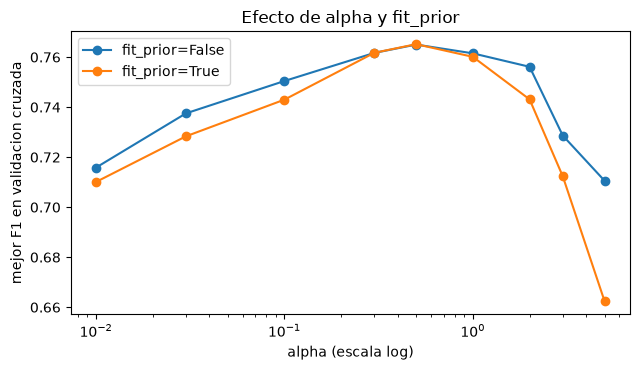

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for fp, g in res.groupby("fit_prior"):
    mejor = g.groupby("alpha")["mean_test_f1"].max()
    ax.plot(mejor.index, mejor.values, marker="o", label=f"fit_prior={fp}")
ax.set_xscale("log")
ax.set_xlabel("alpha (escala log)")
ax.set_ylabel("mejor F1 en validacion cruzada")
ax.set_title("Efecto de alpha y fit_prior")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusion del bloque 3.** La busqueda sube el F1 de validacion cruzada de 0.682 a 0.765, una mejora (0.083) mucho mayor que la desviacion entre folds (~0.02), asi que no es ruido. La ganancia viene sobre todo de conservar las stop words: la lista de sklearn elimina negaciones e intensificadores (not, no, never, very, but) que en una resena cambian el sentido, y quitarlas empeora el F1 a 0.736. El optimo es interior: alpha 0.5 (valores menores sobreajustan, mayores suavizan de mas) y min_df 2 (con 1 entran palabras muy raras). Unigramas y bigramas quedan practicamente empatados, y entre las combinaciones a menos de 0.002 del mejor F1 se elige la mas simple (unigramas, min_df 2, alpha 0.5). `fit_prior` True y False empatan en F1 y solo cambian el equilibrio entre precision y recall; se deja `True` (el valor por defecto, con precision 0.795 y recall 0.740).

## Bloque 4: modelos alternativos

Para saber si Naive Bayes es suficiente, se comparan con la misma validacion cruzada y las mismas metricas tres modelos habituales en texto: regresion logistica, `LinearSVC` y bosque aleatorio (el enunciado sugiere probar un bosque aleatorio para optimizar). Cada uno tiene una busqueda pequena de hiperparametros y puede usar conteos (`CountVectorizer`) o TF-IDF (`TfidfVectorizer`). Todos conservan las stop words, por lo visto en el bloque 3. Naive Bayes entra con la configuracion elegida para tener todo en la misma tabla.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

scoring = {"accuracy": "accuracy", "recall": "recall",
           "precision": "precision", "f1": "f1"}
vectorizadores = [CountVectorizer(min_df=2), TfidfVectorizer(min_df=2)]

# Naive Bayes con la configuracion elegida en el bloque 3
nb_elegido = Pipeline([
    ("vec", CountVectorizer(min_df=2, ngram_range=(1, 1), binary=False, stop_words=None)),
    ("modelo", MultinomialNB(alpha=0.5, fit_prior=True)),
])

espacios = {
    "LogisticRegression": (
        Pipeline([("vec", CountVectorizer()),
                  ("modelo", LogisticRegression(max_iter=2000))]),
        {"vec": vectorizadores,
         "modelo__C": [0.1, 0.3, 1, 3, 10, 30],
         "modelo__class_weight": [None, "balanced"]}),
    "LinearSVC": (
        Pipeline([("vec", CountVectorizer()),
                  ("modelo", LinearSVC())]),
        {"vec": vectorizadores,
         "modelo__C": [0.03, 0.1, 0.3, 1, 3],
         "modelo__class_weight": [None, "balanced"]}),
    "RandomForest": (
        Pipeline([("vec", CountVectorizer()),
                  ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1))]),
        {"vec": vectorizadores,
         "modelo__max_features": ["sqrt", 0.1],
         "modelo__min_samples_leaf": [1, 2],
         "modelo__class_weight": [None, "balanced"]}),
}

def resumen(cvres, i):
    return {"accuracy": cvres["mean_test_accuracy"][i], "recall": cvres["mean_test_recall"][i],
            "precision": cvres["mean_test_precision"][i], "f1": cvres["mean_test_f1"][i],
            "std_f1": cvres["std_test_f1"][i]}

filas = {}
nb_cv = cross_validate(nb_elegido, X_train, y_train, cv=cv, scoring=scoring)
filas["MultinomialNB (bloque 3)"] = {
    "accuracy": nb_cv["test_accuracy"].mean(), "recall": nb_cv["test_recall"].mean(),
    "precision": nb_cv["test_precision"].mean(), "f1": nb_cv["test_f1"].mean(),
    "std_f1": nb_cv["test_f1"].std()}

mejores = {}
for nombre, (pipe, grid) in espacios.items():
    g = GridSearchCV(pipe, grid, scoring=scoring, refit="f1", cv=cv, n_jobs=1)
    g.fit(X_train, y_train)
    mejores[nombre] = g
    filas[nombre] = resumen(g.cv_results_, g.best_index_)

tabla_alt = pd.DataFrame(filas).T.round(3).sort_values("f1", ascending=False)
tabla_alt

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,accuracy,recall,precision,f1,std_f1
LogisticRegression,0.844,0.772,0.779,0.774,0.034
LinearSVC,0.844,0.768,0.781,0.774,0.035
MultinomialNB (bloque 3),0.843,0.740,0.795,0.765,0.022
RandomForest,0.789,0.650,0.716,0.681,0.046


In [9]:
# hiperparametros ganadores de cada alternativa
for nombre, g in mejores.items():
    p = {k: (type(v).__name__ if k == "vec" else v) for k, v in g.best_params_.items()}
    print(nombre, p)

LogisticRegression {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'vec': 'TfidfVectorizer'}
LinearSVC {'modelo__C': 0.1, 'modelo__class_weight': 'balanced', 'vec': 'TfidfVectorizer'}
RandomForest {'modelo__class_weight': 'balanced', 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 2, 'vec': 'CountVectorizer'}


**Conclusion del bloque 4.** La regresion logistica y `LinearSVC` obtienen F1 0.774, solo 0.009 por encima de MultinomialNB (0.765), una diferencia menor que la desviacion entre folds (0.02 a 0.035): es un empate tecnico, no una ventaja demostrada. Naive Bayes destaca por precision (0.795) y por ser el modelo mas simple y estable (desviacion 0.022), mientras que los lineales detectan algo mas de positivas (recall 0.77). El bosque aleatorio queda claramente por debajo (F1 0.681): con unos 700 textos y miles de palabras casi siempre en cero, los arboles no encuentran divisiones utiles. Como el proyecto trata de Naive Bayes y no hay ventaja clara, se mantiene como modelo final, y se evalua en test junto a la regresion logistica solo como referencia.

## Bloque 5: evaluacion final en test

El conjunto de test (178 resenas, unas 61 positivas) no se ha usado hasta ahora. Se usa una sola vez: se reentrena en todo el train la configuracion elegida de Naive Bayes y se evalua. Para comparar, se hace lo mismo con la mejor alternativa de la validacion cruzada (regresion logistica). Como referencia, un modelo que siempre dice "negativa" tiene accuracy 0.657.

Positivas en test: 61 de 178
                    accuracy  recall  precision     f1
MultinomialNB          0.843    0.77      0.770  0.770
LogisticRegression     0.854    0.77      0.797  0.783

              precision    recall  f1-score   support

    negativa      0.880     0.880     0.880       117
    positiva      0.770     0.770     0.770        61

    accuracy                          0.843       178
   macro avg      0.825     0.825     0.825       178
weighted avg      0.843     0.843     0.843       178



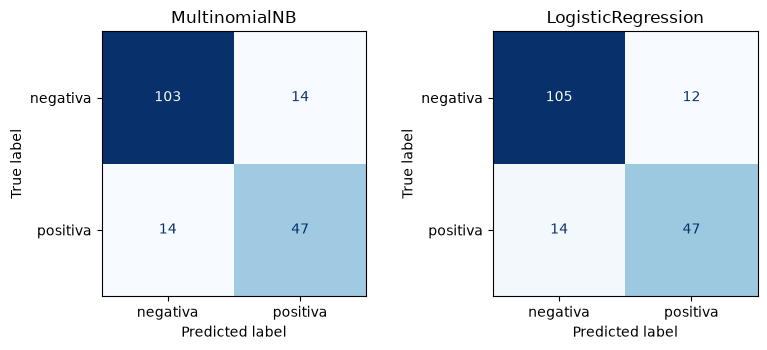

In [10]:
import os, pickle
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

finalistas = {
    "MultinomialNB": nb_elegido,
    "LogisticRegression": mejores["LogisticRegression"].best_estimator_,
}

filas, predicciones = {}, {}
for nombre, modelo in finalistas.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    filas[nombre] = {"accuracy": accuracy_score(y_test, pred), "recall": recall_score(y_test, pred),
                     "precision": precision_score(y_test, pred), "f1": f1_score(y_test, pred)}

tabla_test = pd.DataFrame(filas).T.round(3)
print("Positivas en test:", int(y_test.sum()), "de", len(y_test))
print(tabla_test.to_string())
print()
print(classification_report(y_test, predicciones["MultinomialNB"], target_names=["negativa", "positiva"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["negativa", "positiva"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [11]:
# palabras que mas inclinan a Naive Bayes hacia cada clase (cociente de probabilidades logaritmicas)
vec = nb_elegido.named_steps["vec"]
nbm = nb_elegido.named_steps["modelo"]
palabras = np.array(vec.get_feature_names_out())
diferencia = nbm.feature_log_prob_[1] - nbm.feature_log_prob_[0]
orden = np.argsort(diferencia)
print("Mas negativas:", ", ".join(palabras[orden[:12]]))
print("Mas positivas:", ", ".join(palabras[orden[::-1][:12]]))

Mas negativas: wechat, twitter, cant, error, cannot, hangouts, sucks, uninstall, network, loot, these, unable
Mas positivas: birds, angry, brilliant, hamro, doubt, family, caps, slack, şŕľ, fantastic, definitely, challenges


In [12]:
# guardar el pipeline completo (vectorizador + modelo) y comprobar que se recarga igual
os.makedirs("../models", exist_ok=True)
ruta = "../models/naive_bayes_multinomial_alpha0-5_mindf2_unigramas_seed42.pkl"
with open(ruta, "wb") as f:
    pickle.dump(nb_elegido, f)

with open(ruta, "rb") as f:
    recargado = pickle.load(f)
print("Predicciones identicas tras recargar:", bool((recargado.predict(X_test) == predicciones["MultinomialNB"]).all()))
ejemplos = ["love this app, works great", "it does not work, a waste of time", "not bad at all"]
print(dict(zip(ejemplos, recargado.predict(ejemplos).tolist())))

Predicciones identicas tras recargar: True
{'love this app, works great': 1, 'it does not work, a waste of time': 0, 'not bad at all': 0}


**Conclusion final.** En test (178 resenas, 61 positivas) Naive Bayes alcanza accuracy 0.843, precision 0.770, recall 0.770 y F1 0.770, frente a una accuracy de 0.657 al predecir siempre "negativa". El F1 coincide con el de validacion cruzada (0.765), asi que no hay sobreajuste visible. La regresion logistica queda en F1 0.783 (accuracy 0.854): con este tamano de test es una diferencia de una o dos resenas, por lo que no se considera superior y se mantiene Naive Bayes, que es el objetivo del proyecto. El modelo acierta el 88 % de las negativas y el 77 % de las positivas, es decir, falla mas en la clase minoritaria.

Limitaciones. (1) Con solo 61 positivas, un acierto mas o menos mueve el recall 1.6 puntos, asi que todas las cifras tienen un margen de error amplio. (2) Entre las palabras mas informativas aparecen nombres de apps (birds, angry, slack, wechat, twitter, hangouts): parte de lo aprendido es la app y no el sentimiento, y puede generalizar peor a apps nuevas. (3) La bolsa de palabras no entiende la negacion: "not bad at all" se clasifica como negativa. El Pipeline completo (vectorizador y modelo) queda guardado en `models/naive_bayes_multinomial_alpha0-5_mindf2_unigramas_seed42.pkl`.